In [78]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/__results__.html
/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/__notebook__.ipynb
/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/__output__.json
/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/tips_extended_cleaned.csv
/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/custom.css
/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/__results___files/__results___13_1.png


# Import Libraries

In [79]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Loading the Dataset

In [80]:
df = pd.read_csv("/kaggle/input/notebooks/sudeeppattanshetty/tips-extended-analysis-2/tips_extended_cleaned.csv")
df.sample(5)

,Bill,Number_of_People,Tips,Arrived_in_cleaned,Time_of_visit_cleaned
33,121,6,21,2,2
38,45,5,7,3,3
14,165,1,21,2,0
101,80,1,9,2,0
72,226,1,19,1,2


# Train-test split

In [81]:
df.shape # No of rows & columns

(103, 5)

In [82]:
test_ratio = 0.1 # 10% for testing, 90% of training
data_size = df.shape[0]
test_size = int(data_size * test_ratio)
train_size = data_size - test_size
(train_size, test_size)

(93, 10)

In [83]:
df = df.sample(frac=1)   # Randomize the records in df
train_df = df.head(train_size)
test_df = df.tail(test_size)
(train_df.shape[0], test_df.shape[0])

(93, 10)

# Convert train & test data to numpy

In [84]:
df.columns

Index(['Bill', 'Number_of_People', 'Tips', 'Arrived_in_cleaned',
       'Time_of_visit_cleaned'],
      dtype='object')

In [85]:
feature_columns = ['Bill', 'Number_of_People', 'Arrived_in_cleaned',
       'Time_of_visit_cleaned']

train_x_df = train_df.loc[:, feature_columns]
train_y_df = train_df.loc[:, ['Tips']]
test_x_df = test_df.loc[:, feature_columns]
test_y_df = test_df.loc[:, ['Tips']]

In [86]:
train_x = train_x_df.to_numpy() # 93 * 5
train_y = train_y_df.to_numpy().reshape(-1) # 93 * 1 ====> 1
test_x = test_x_df.to_numpy() # 10 * 5
test_y = test_y_df.to_numpy().reshape(-1) # 10 * 1 ====> 1

# Initiate the algorithm

In [87]:
logistic_model = LogisticRegression(solver='liblinear', C=50)

# Train the model

In [88]:
logistic_model.fit(train_x, train_y)

LogisticRegression(C=50, solver='liblinear')

# Test the model

In [89]:
predicted = logistic_model.predict(test_x)
print(f'Actual: {test_y}')
print(f'Predicted: {predicted}')

Actual: [ 1  5 20  4  1 12 22 24  4 30]
Predicted: [ 1  2 37  1  1 24 20 19  4 32]


In [90]:
mean_squared_error(test_y, predicted)

48.4

In [91]:
mean_absolute_error(test_y, predicted)

4.4

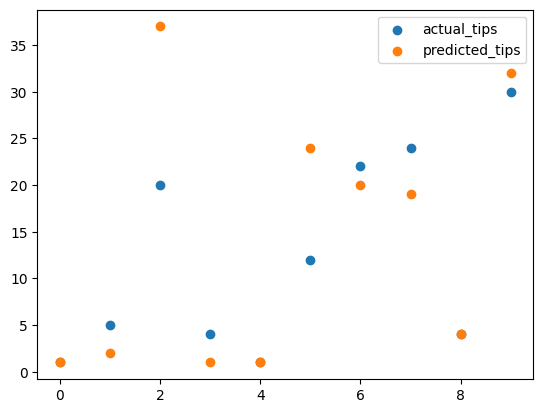

In [92]:
import matplotlib.pyplot as plt
ts = len(test_y)
plt.scatter(range(ts), test_y, label='actual_tips')
plt.scatter(range(ts), predicted, label='predicted_tips')
plt.legend()

# Predict on real-world data

In [93]:
sample_in = [120, 6, 2, 2]
sample_result = logistic_model.predict([sample_in])
sample_result[0]

np.int64(16)